In [4]:
from sklearn.datasets import fetch_california_housing

# Load the California housing dataset as a pandas DataFrame
data = fetch_california_housing(as_frame=True)

# Extract the complete dataset
df = data.frame

# Verify that the dataset is loaded
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset Shape: (20640, 9)
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [6]:
# Separate features and target
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Insect the dataset
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Check data types
print(df.dtypes)

# Check missing values
print(df.isnull().sum())

# View summary statistics
display(df.describe())


Features Shape: (20640, 8)
Target Shape: (20640,)
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


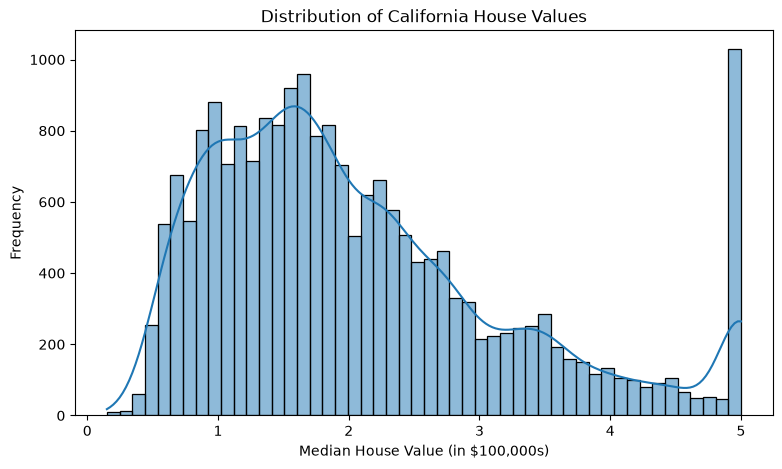

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of median house values
plt.figure(figsize=(9,5))

sns.histplot(data=df, x='MedHouseVal', bins=50, kde=True)

plt.title("Distribution of California House Values")
plt.xlabel("Median House Value (in $100,000s)")
plt.ylabel("Frequency")

plt.show()

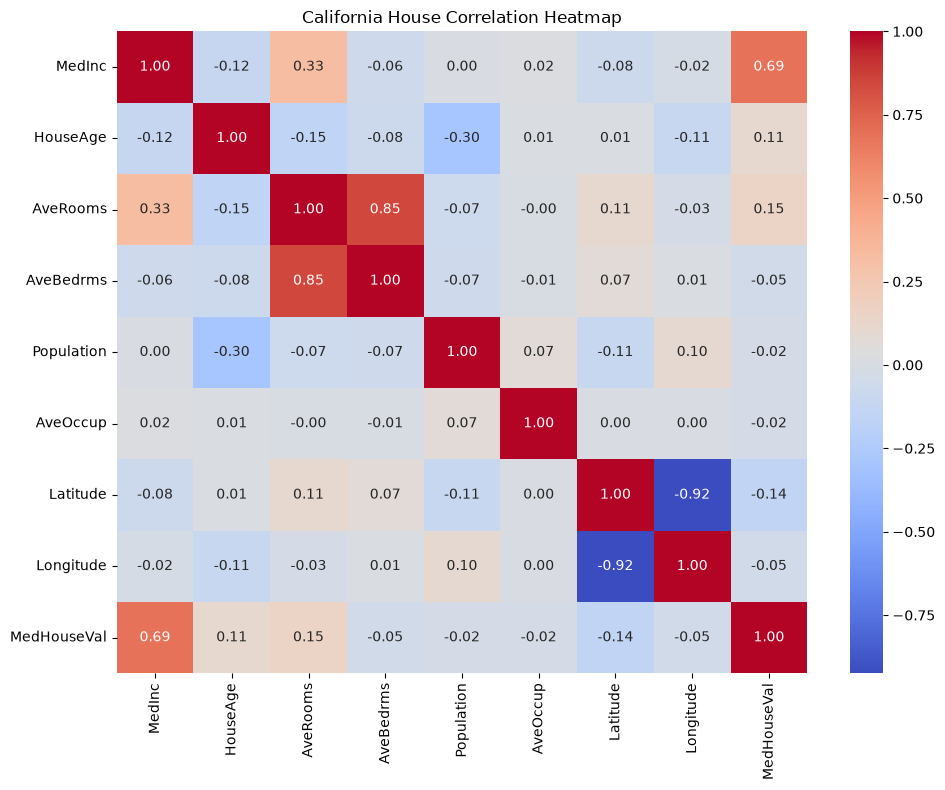

In [8]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("California House Correlation Heatmap")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

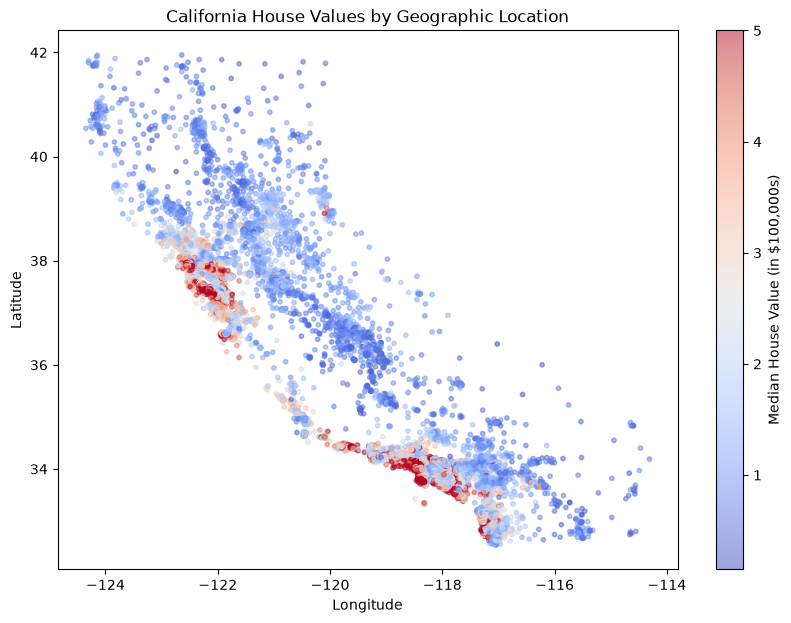

In [9]:
# Visualize house values by geographic location
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df['Longitude'],
    df['Latitude'],
    c=df['MedHouseVal'],
    cmap='coolwarm',
    s=10,
    alpha=0.5
)

plt.colorbar(scatter, label='Median House Value (in $100,000s)')

plt.title("California House Values by Geographic Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show

In [10]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Verify the shapes of the training and testing sets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [12]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to the test data
X_test_scaled = scaler.transform(X_test)

# Verify the transformation
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("Training means:", X_train_scaled.mean(axis=0).round(2))
print("Training std:", X_train_scaled.std(axis=0).round(2))

Training shape: (16512, 8)
Testing shape: (4128, 8)
Training means: [-0. -0.  0. -0.  0.  0.  0.  0.]
Training std: [1. 1. 1. 1. 1. 1. 1. 1.]


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    root_mean_squared_error
)

# Initialize the Linear Regression model
model = LinearRegression()

# Train using scaled training features
model.fit(X_train_scaled, y_train)

# Predict on unseen test data
y_pred = model.predict(X_test_scaled)

# Evaluate performance
r2 = r2_score(y_test, y_pred)
mae = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print(f"R² Score: {r2:.4f}")
print(f"MAE: ${mae * 100000:,.2f}")
print(f"RMSE: ${rmse * 100000:,.2f}")

R² Score: 0.5758
Mean Absolute Error: 55589.16
Root Mean Squared Error: 74558.14


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error
)

# Convert errors to dollar units
mae = mean_absolute_error(y_test, y_pred) * 100_000
mse = mean_squared_error(y_test, y_pred) * (100_000 ** 2)
rmse = root_mean_squared_error(y_test, y_pred) * 100_000

# Print the evaluation metrics
print(f"MAE: ${mae:,.2f}")
print(f"MSE: {mse:,.2f} dollars squared")
print(f"RMSE: ${rmse:,.2f}")

MAE: $53,320.01
MSE: 5,558,915,986.95 dollars squared
RMSE: $74,558.14


In [19]:
import pandas as pd

# Extract the learned coefficients
coefficients = pd.Series(
    model.coef_ * 100_000,  # Scale coefficients to dollar units
    index=X.columns, # Use feature names as index
    name="Coefficient" # Name the series for clarity
)

# Sort by absolute coefficient magnitude
coefficients = coefficients.sort_values(
    key=abs,
    ascending=False
)

# Display coefficients and intercept
display(coefficients.to_frame())

print(f"Intercept: ${model.intercept_ * 100_000:,.2f}")

,Coefficient
Latitude,-89692.887664
Longitude,-86984.177524
MedInc,85438.303093
AveBedrms,33925.949059
AveRooms,-29441.013447
HouseAge,12254.623808
AveOccup,-4082.910309
Population,-230.772315


Intercept: $207,194.69


<function matplotlib.pyplot.show(close=None, block=None)>

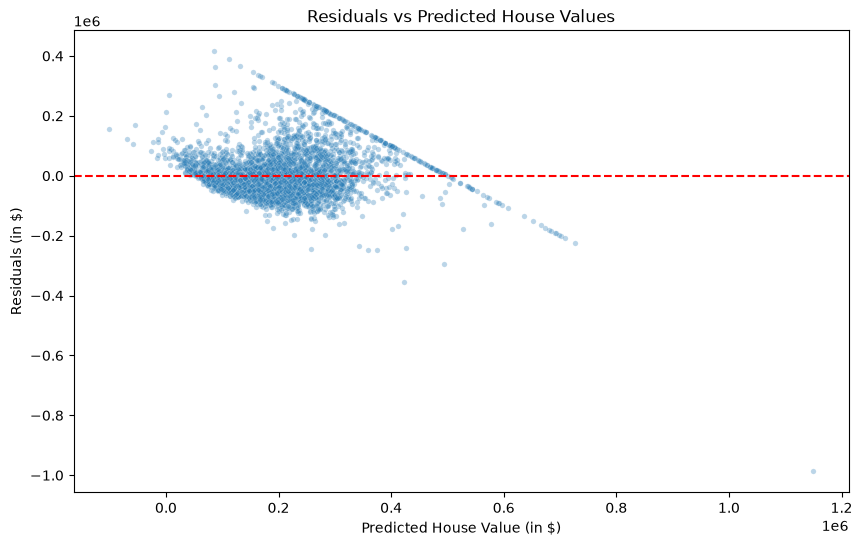

In [20]:
# Calculate residuals in dollars
residuals = (y_test - y_pred) * 100_000
predictions = y_pred * 100_000

# Visualize prediction errors
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=predictions,
    y=residuals,
    alpha=0.3,
    s=15
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted House Values")
plt.xlabel("Predicted House Value (in $)")
plt.ylabel("Residuals (in $)")

plt.show